# 16 · Machine Learning: Predicting Bike Demand

In topic 15 we **explored** the bike-sharing data and found what drives demand: hour of day, workday vs day off, temperature, weather and growth.
Now we build a model that **predicts** how many bikes will be rented in a given hour, so the company can plan bikes and staff in advance.

This is **supervised learning**, specifically **regression**:
- **Features (X):** what we know in advance: hour, day type, weather forecast, temperature...
- **Target (y):** what we want to predict: the number of rides in that hour.
- The model learns the relationship from past data, and we measure it on data it has **never seen**.

Read the concepts in [README.md](README.md).

In [1]:
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from features import CATEGORICAL, FEATURES, NUMERIC, TARGET, as_numbers, is_category_mask, tree_preprocessing

sys.path.insert(0, "../13_visualisation")
import chart_style as cs

cs.apply()
import sklearn
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


# 1. Data: features and target

In [2]:
df = pd.read_csv("../15_eda_project/data/bike_hourly_clean.csv", parse_dates=["datetime", "date"])
df = df.sort_values("datetime").reset_index(drop=True)
df[["datetime", "hour", "weekday", "workingday", "weather", "temp_c", "humidity", "rides"]].head()

,datetime,hour,weekday,workingday,weather,temp_c,humidity,rides
0,2011-01-01 00:00:00,0,Saturday,False,Clear,9.8,81.0,16
1,2011-01-01 01:00:00,1,Saturday,False,Clear,9.0,80.0,40
2,2011-01-01 02:00:00,2,Saturday,False,Clear,9.0,80.0,32
3,2011-01-01 03:00:00,3,Saturday,False,Clear,9.8,75.0,13
4,2011-01-01 04:00:00,4,Saturday,False,Clear,9.8,75.0,1


### Which columns can the model use?

Ask: **would I know this value at the moment I need the prediction?**

| Column | Use it? | Why |
|--------|---------|-----|
| hour, weekday, month, year, workingday, holiday, season | ✅ | Known from the calendar |
| weather, temp_c, humidity, windspeed | ✅ | Known from the weather forecast |
| **casual, registered** | ❌ **Leakage!** | They add up to the answer (`rides = casual + registered`), and we only know them *after* the hour is over |
| datetime, date | ❌ | Identifiers. The model would memorise dates instead of learning patterns |

In [3]:
# The feature lists live in features.py, shared with predict.py
print("categorical:", CATEGORICAL)
print("numeric:    ", NUMERIC)
print("missing humidity values (the broken sensor from topic 15):", df["humidity"].isna().sum())

categorical: ['weekday', 'season', 'weather']
numeric:     ['hour', 'month', 'year', 'workingday', 'holiday', 'temp_c', 'humidity', 'windspeed']
missing humidity values (the broken sensor from topic 15): 22


# 2. Split the data: train on the past, test on the future

We'll use the model to predict the **future**, so we must test it the same way: train on **Jan 2011 – Aug 2012**, test on **Sep – Dec 2012**.

A random split would put 3 pm in the test set and 2 pm and 4 pm of the same day in the training set. The model could then "cheat" by looking at neighbouring hours. We'll measure how much this inflates the score in section 8.

In [4]:
train = df[df["datetime"] < "2012-09-01"]
test = df[df["datetime"] >= "2012-09-01"]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f"train: {len(train):,} hours  ({train['date'].min():%b %Y} – {train['date'].max():%b %Y})")
print(f"test:  {len(test):,} hours  ({test['date'].min():%b %Y} – {test['date'].max():%b %Y})")
print(f"average rides per hour in the test period: {y_test.mean():.0f}")

train: 14,491 hours  (Jan 2011 – Aug 2012)
test:  2,888 hours  (Sep 2012 – Dec 2012)
average rides per hour in the test period: 240


# 3. How do we measure a model?

| Metric | Meaning | Here |
|--------|---------|------|
| **MAE** (mean absolute error) | The average size of the mistakes | "On average we're off by X bikes an hour". The easiest to explain |
| **RMSE** (root mean squared error) | Like MAE, but big mistakes count much more | Punishes the hours where we're badly wrong |
| **R²** | The share of the variation explained: 1 = perfect, 0 = no better than always guessing the average | Comparable across problems |

### Always start with a baseline

A model is only useful if it beats a simple rule. Our two baselines:
1. Always predict the training average.
2. Predict the average for that **hour on that type of day** (workday or day off). This is the pattern topic 15 found.

In [5]:
results = {}

def evaluate(name, predictions):
    results[name] = {
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": root_mean_squared_error(y_test, predictions),
        "R²": r2_score(y_test, predictions),
    }
    return pd.Series(results[name]).round(3)

evaluate("Baseline: overall average", np.full(len(y_test), y_train.mean()))

MAE     170.509
RMSE    226.027
R²       -0.078
dtype: float64

In [6]:
hourly_average = train.groupby(["workingday", "hour"])[TARGET].mean()
baseline_predictions = hourly_average.reindex(pd.MultiIndex.from_frame(test[["workingday", "hour"]])).to_numpy()
evaluate("Baseline: hour × workday average", baseline_predictions)

MAE      94.780
RMSE    138.527
R²        0.595
dtype: float64

The simple rule already explains **60%** of the variation (R² = 0.60). Every model below has to beat **MAE ≈ 95**.

# 4. Linear regression

Linear regression learns one weight per feature and adds them up. To use text categories, we **one-hot encode** them (one 0/1 column per category). We also treat **hour** as a category: a straight line can't capture "a peak at 8 and 17, low at night".

A **Pipeline** bundles the preprocessing and the model. This matters: the encoder and scaler learn **only from the training data**, so no information from the test set leaks in.

In [7]:
linear = make_pipeline(
    ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL + ["hour", "month"]),
        ("numbers", StandardScaler(), ["year", "workingday", "holiday", "temp_c", "humidity", "windspeed"]),
    ]),
    LinearRegression(),
)
# The few missing humidity values are filled with the TRAINING median
humidity_median = X_train["humidity"].median()
X_train = X_train.fillna({"humidity": humidity_median})
X_test = X_test.fillna({"humidity": humidity_median})

linear.fit(X_train, y_train)
evaluate("Linear regression", linear.predict(X_test))

MAE      97.444
RMSE    132.470
R²        0.630
dtype: float64

**Barely better than the simple rule!** Why? Linear regression *adds* effects: "8 am adds X rides, a workday adds Y rides". But the 8 am peak only happens **on workdays**. The effects **interact**, and a plain linear model can't express that.

### Feature engineering: give the model the interaction

We can create a new feature that combines hour and day type, like `"8-workday"` or `"8-day off"`:

In [8]:
def add_hour_type(X):
    X = X.copy()
    X["hour_type"] = X["hour"].astype(str) + np.where(X["workingday"] == 1, "-work", "-off")
    return X

linear_plus = make_pipeline(
    ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL + ["hour_type", "month"]),
        ("numbers", StandardScaler(), ["year", "holiday", "temp_c", "humidity", "windspeed"]),
    ]),
    LinearRegression(),
)
linear_plus.fit(add_hour_type(X_train), y_train)
evaluate("Linear + hour×workday feature", linear_plus.predict(add_hour_type(X_test)))

MAE      76.391
RMSE    103.176
R²        0.775
dtype: float64

One well-chosen feature, based on what the EDA showed, makes a clear improvement. **Domain knowledge beats blind modelling.**

# 5. Tree-based models

Decision trees split the data with questions like *"is hour ≥ 7?"* then *"is it a workday?"*, so they discover **interactions automatically**.
- **Random forest:** hundreds of trees, each trained on a random part of the data, with their predictions averaged.
- **Gradient boosting:** trees built one after another, each correcting the previous trees' mistakes. It's often the strongest choice for tables of data.

Trees don't need scaling. For categories we use simple number codes (`OrdinalEncoder`), and gradient boosting is told which columns are categories.

In [9]:
# tree_preprocessing() comes from features.py: categories -> number codes, numbers -> floats
forest = make_pipeline(tree_preprocessing(),
                       RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=0))
forest.fit(X_train, y_train)
evaluate("Random forest", forest.predict(X_test))

MAE     49.725
RMSE    75.342
R²       0.880
dtype: float64

In [10]:
is_category = is_category_mask()
boosting = make_pipeline(tree_preprocessing(),
                         HistGradientBoostingRegressor(categorical_features=is_category, max_iter=400,
                                                       learning_rate=0.08, random_state=0))
boosting.fit(X_train, y_train)
evaluate("Gradient boosting", boosting.predict(X_test))

MAE     44.956
RMSE    67.447
R²       0.904
dtype: float64

# 6. Comparing the models

In [11]:
comparison = pd.DataFrame(results).T.sort_values("MAE")
comparison.style.format({"MAE": "{:.1f}", "RMSE": "{:.1f}", "R²": "{:.3f}"})

,MAE,RMSE,R²
Gradient boosting,45.0,67.4,0.904
Random forest,49.7,75.3,0.880
Linear + hour×workday feature,76.4,103.2,0.775
Baseline: hour × workday average,94.8,138.5,0.595
Linear regression,97.4,132.5,0.630
Baseline: overall average,170.5,226.0,-0.078


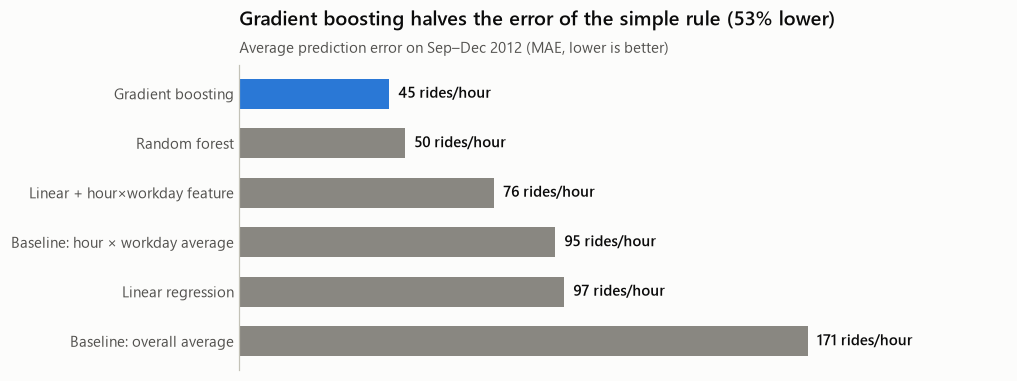

In [12]:
ordered = comparison["MAE"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [cs.PRIMARY if name == ordered.index[-1] else cs.MUTED for name in ordered.index]
bars = ax.barh(ordered.index, ordered.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0f} rides/hour" for v in ordered.values], padding=6, fontweight="semibold")
ax.xaxis.set_visible(False)
ax.grid(False)
ax.spines["bottom"].set_visible(False)
ax.set_xlim(0, ordered.max() * 1.35)
best = ordered.index[-1]
improvement = 1 - ordered.iloc[-1] / results["Baseline: hour × workday average"]["MAE"]
cs.title(ax, f"{best} halves the error of the simple rule ({improvement:.0%} lower)",
         "Average prediction error on Sep–Dec 2012 (MAE, lower is better)")
fig.savefig("images/model_comparison.png")
plt.show()

# 7. Tuning with time-series cross-validation

A single test split can be lucky or unlucky. **Cross-validation** trains and tests several times on different parts of the data.

For time data we use **`TimeSeriesSplit`**: each fold trains on the past and validates on the period right after it, so we never train on the future. We use only the **training period** here, and keep the test set untouched for the final check.

In [13]:
cv = TimeSeriesSplit(n_splits=4)
grid = GridSearchCV(
    boosting,
    param_grid={
        "histgradientboostingregressor__learning_rate": [0.05, 0.1],
        "histgradientboostingregressor__max_iter": [200, 400],
        "histgradientboostingregressor__max_leaf_nodes": [31, 63],
    },
    cv=cv, scoring="neg_mean_absolute_error",
)
grid.fit(X_train, y_train)

print("best settings:", {k.split("__")[1]: v for k, v in grid.best_params_.items()})
print(f"cross-validated MAE on the training period: {-grid.best_score_:.1f}")
tuned = grid.best_estimator_
evaluate("Gradient boosting (tuned)", tuned.predict(X_test))

best settings: {'learning_rate': 0.1, 'max_iter': 400, 'max_leaf_nodes': 31}
cross-validated MAE on the training period: 51.0


MAE     46.868
RMSE    69.449
R²       0.898
dtype: float64

Tuning is worth trying, but it's usually a **small** gain compared with good features and the right type of model. If the tuned model isn't clearly better on the test set, the simpler settings are fine.

# 8. Two traps that make models look better than they are

### Trap 1: a random split on time data

In [14]:
X_all = df[FEATURES].fillna({"humidity": humidity_median})
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_all, df[TARGET], test_size=0.2, random_state=0)
random_split_model = make_pipeline(tree_preprocessing(),
                                   HistGradientBoostingRegressor(categorical_features=is_category, max_iter=400,
                                                                 learning_rate=0.08, random_state=0))
random_split_model.fit(Xr_train, yr_train)
random_mae = mean_absolute_error(yr_test, random_split_model.predict(Xr_test))
print(f"MAE with a RANDOM split:       {random_mae:.1f}   <- looks great...")
print(f"MAE with a TIME split (honest): {results['Gradient boosting']['MAE']:.1f}   <- what you'd really get")

MAE with a RANDOM split:       24.9   <- looks great...
MAE with a TIME split (honest): 45.0   <- what you'd really get


The random split looks much better, because the model sees the hours on **both sides** of each test hour (the same day, the same weather). In real use you never have tomorrow's data, so the **time split is the honest number**.

### Trap 2: data leakage

What if we forgot to remove the `registered` column?

In [15]:
leaky_features = FEATURES + ["registered"]
leaky_preprocessing = tree_preprocessing()
leaky_preprocessing.transformers[1] = ("numbers", FunctionTransformer(as_numbers), NUMERIC + ["registered"])
leaky = make_pipeline(leaky_preprocessing,
                      HistGradientBoostingRegressor(categorical_features=is_category_mask(extra_numeric=1), random_state=0))
leaky.fit(train[leaky_features].fillna({"humidity": humidity_median}), y_train)
leaky_r2 = r2_score(y_test, leaky.predict(test[leaky_features].fillna({"humidity": humidity_median})))
print(f"R² with the leaky column: {leaky_r2:.3f}   <- 'amazing', and useless")

R² with the leaky column: 0.987   <- 'amazing', and useless


An almost perfect score is a **warning sign**, not a success. `registered` is part of the answer and isn't known in advance. In the real world this model would fail completely, because at prediction time the column wouldn't exist.

> 💡 **If a result looks too good to be true, look for leakage first.**

# 9. How good is the final model, really?

We'll use plain gradient boosting (or the tuned version if it was clearly better) and look beyond a single number.

In [16]:
final = tuned if results["Gradient boosting (tuned)"]["MAE"] < results["Gradient boosting"]["MAE"] - 1 else boosting
predictions = pd.Series(final.predict(X_test), index=test.index).clip(lower=0)   # rides can't be negative
mae = mean_absolute_error(y_test, predictions)
print(f"final model MAE: {mae:.1f} rides/hour  (the average hour has {y_test.mean():.0f} rides)")
print(f"R²: {r2_score(y_test, predictions):.3f}")

final model MAE: 44.9 rides/hour  (the average hour has 240 rides)
R²: 0.904


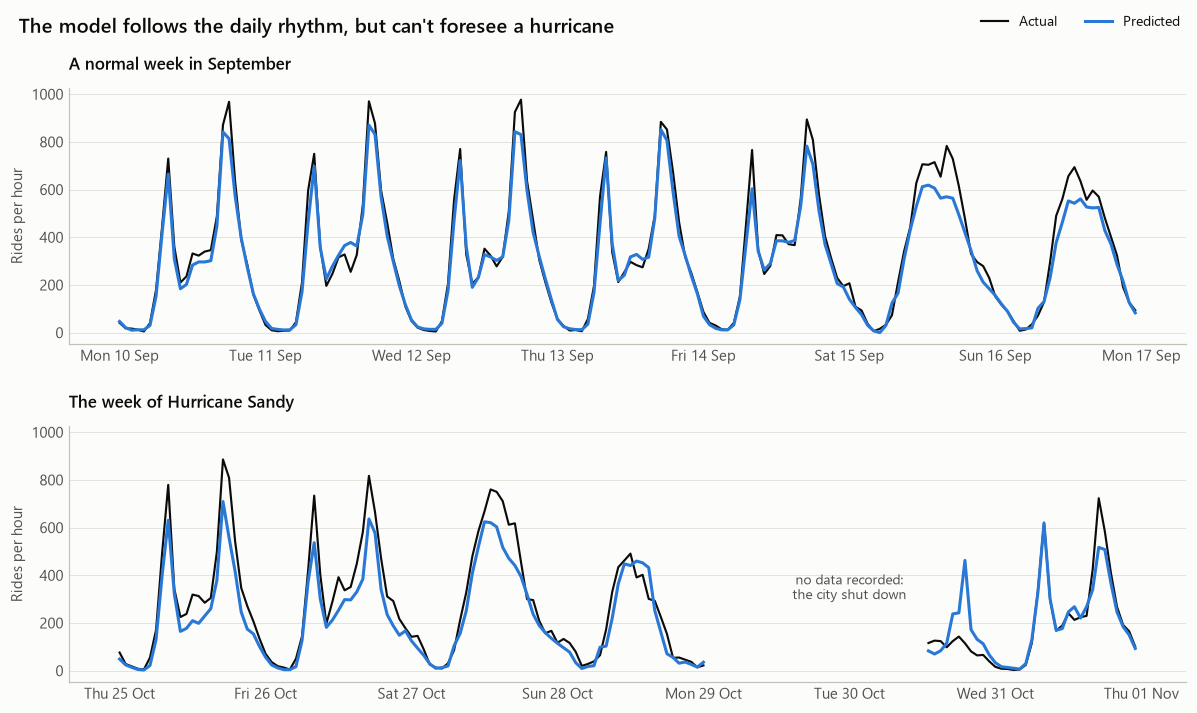

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharey=True)
weeks = [("2012-09-10", "2012-09-17", "A normal week in September"),
         ("2012-10-25", "2012-11-01", "The week of Hurricane Sandy")]
for ax, (start, end, label) in zip(axes, weeks):
    window = (test["datetime"] >= start) & (test["datetime"] < end)
    # Reindex to every hour, so missing hours show as GAPS instead of a made-up straight line
    every_hour = pd.date_range(start, end, freq="h", inclusive="left")
    actual = y_test[window].set_axis(test.loc[window, "datetime"]).reindex(every_hour)
    predicted = predictions[window].set_axis(test.loc[window, "datetime"]).reindex(every_hour)
    ax.plot(every_hour, actual, color=cs.INK, linewidth=1.4, label="Actual")
    ax.plot(every_hour, predicted, color=cs.PRIMARY, linewidth=2, label="Predicted")
    ax.set_title(label, fontsize=11)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d %b"))
    ax.set_ylabel("Rides per hour")
    cs.only_grid(ax, "y")
axes[1].annotate("no data recorded:\nthe city shut down", (pd.Timestamp("2012-10-30 00:00"), 300), ha="center",
                 fontsize=9, color=cs.INK_SECONDARY)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncols=2, bbox_to_anchor=(0.99, 1.0))
fig.suptitle("The model follows the daily rhythm, but can't foresee a hurricane", x=0.02, ha="left",
             fontsize=13, fontweight="semibold")
fig.tight_layout(h_pad=2)
fig.savefig("images/actual_vs_predicted.png")
plt.show()

In a normal week, the predictions follow the morning and evening peaks closely. During **Hurricane Sandy**, the city shut down. The model predicted a normal-ish day because nothing in its features says "hurricane". **A model only knows what's in its features and its training data.** In practice, an operator would override the forecast for such events.

### Where are the errors largest?

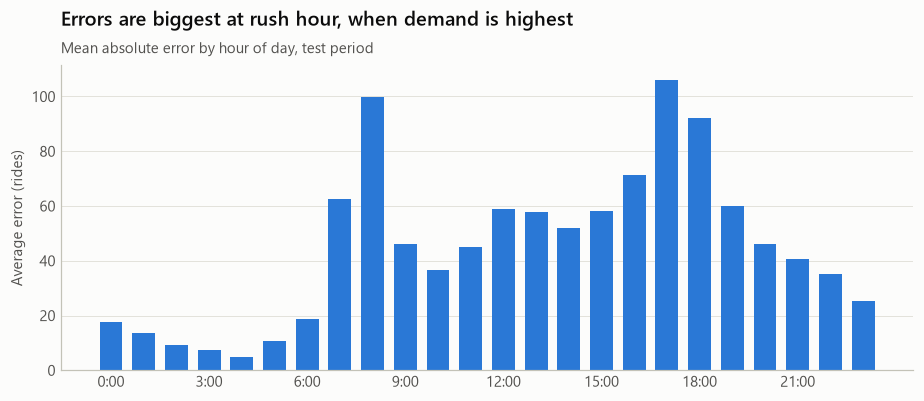

In [18]:
errors = (predictions - y_test).abs()
by_hour = errors.groupby(test["hour"]).mean()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(by_hour.index, by_hour.values, color=cs.PRIMARY, width=0.7)
ax.set_xticks(range(0, 24, 3), [f"{h}:00" for h in range(0, 24, 3)])
ax.set_ylabel("Average error (rides)")
cs.only_grid(ax, "y")
cs.title(ax, "Errors are biggest at rush hour, when demand is highest",
         "Mean absolute error by hour of day, test period")
plt.show()

Bigger hours have bigger errors in absolute terms. That's normal, and it's also where getting it right matters most for rebalancing bikes.

# 10. What does the model rely on?

**Permutation importance:** shuffle one feature at a time and measure how much worse the predictions get. A big drop means the model depends on that feature.

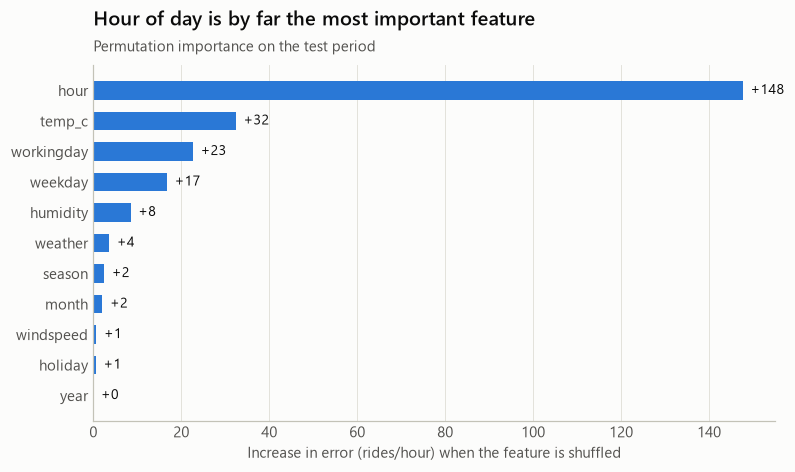

In [19]:
importance = permutation_importance(final, X_test, y_test, scoring="neg_mean_absolute_error",
                                    n_repeats=5, random_state=0)
importance = pd.Series(importance.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(importance.index, importance.values, color=cs.PRIMARY, height=0.6)
ax.bar_label(bars, labels=[f"+{v:.0f}" for v in importance.values], padding=5, fontsize=9)
ax.set_xlabel("Increase in error (rides/hour) when the feature is shuffled")
cs.only_grid(ax, "x")
cs.title(ax, "Hour of day is by far the most important feature", "Permutation importance on the test period")
fig.savefig("images/feature_importance.png")
plt.show()

This matches the EDA in topic 15: **hour** drives demand most, then **temperature** and the **type of day** (workday, weekday). When a model agrees with what you found by exploring, that's a good sign it learned real patterns.

**Why is `year` at 0, when we know demand grew 65%?** Every test row is from 2012, so shuffling `year` *within the test set* changes nothing. Permutation importance only measures features that **vary in the data you evaluate on**. The model does use `year` (it's how it learned that 2012 is busier), but this test can't show it. Always ask what a metric can and can't see.

# 11. Save the model and use it

We've measured the method honestly. For the **production** model we now retrain on **all** the data (2011 to Dec 2012): more data, including the most recent months, gives better forecasts.

The code lives in [train.py](train.py) and [predict.py](predict.py), so the model can be used without the notebook. The whole pipeline (preprocessing + model) is saved as **one file**.

In [20]:
from train import train_and_save

model_file = train_and_save()   # retrains build_model() from features.py on all rows
print("saved", model_file.name)

saved bike_demand.joblib


In [21]:
# Tomorrow: what demand should we plan for?
saved = joblib.load("models/bike_demand.joblib")
scenarios = pd.DataFrame([
    {"label": "Workday 8am, 22°C, clear",     "hour": 8,  "weekday": "Tuesday",  "workingday": 1, "weather": "Clear",             "temp_c": 22},
    {"label": "Workday 8am, 12°C, rain",      "hour": 8,  "weekday": "Tuesday",  "workingday": 1, "weather": "Light rain / snow", "temp_c": 12},
    {"label": "Saturday 2pm, 26°C, clear",    "hour": 14, "weekday": "Saturday", "workingday": 0, "weather": "Clear",             "temp_c": 26},
    {"label": "Workday 3am, 18°C, clear",     "hour": 3,  "weekday": "Tuesday",  "workingday": 1, "weather": "Clear",             "temp_c": 18},
]).assign(month=6, year=2012, holiday=0, season="Spring", humidity=60.0, windspeed=12.0)
scenarios["predicted rides"] = saved["model"].predict(scenarios[saved["features"]]).clip(min=0).round()
scenarios[["label", "predicted rides"]]

,label,predicted rides
0,"Workday 8am, 22°C, clear",721.0
1,"Workday 8am, 12°C, rain",432.0
2,"Saturday 2pm, 26°C, clear",627.0
3,"Workday 3am, 18°C, clear",15.0


# 12. Summary

| Step | What we did | Why it matters |
|------|-------------|----------------|
| Features | Only used values known **before** the hour | Avoids leakage |
| Split | Trained on the past, tested on the future | Honest estimate of real performance |
| Baselines | Average, and average per hour × workday | A model must beat simple rules to be worth it |
| Linear model | Weak until we added an hour × workday feature | Interactions matter; domain knowledge helps |
| Trees | Gradient boosting was best | Learns interactions automatically |
| Tuning | `GridSearchCV` with `TimeSeriesSplit` | Small gains; never tune on the test set |
| Evaluation | MAE, R², errors by hour, a real week vs a hurricane week | One number never tells the whole story |
| Explanation | Permutation importance | Checks the model learned sensible patterns |
| Deployment | One saved pipeline file | Ready to use in an app |

**Next:** topic 17, the capstone, combines everything into one end-to-end project.